In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, OrdinalEncoder, PowerTransformer
from category_encoders import TargetEncoder

# ÚNICA ENTRADA del pipeline
RUTA_ENTRADA = "S04_PD_Lozano_DatasetImputacionInicial.csv"
df = pd.read_csv(RUTA_ENTRADA)
print("Entrada:", RUTA_ENTRADA, "->", df.shape)

Entrada: S04_PD_Lozano_DatasetImputacionInicial.csv -> (589386, 22)


## Etapa 1: Limpieza de inconsistencias y duplicados

In [2]:
import pandas as pd


def limpiar_inconsistencias_semana6(df):
    """
    Limpieza de inconsistencias de texto, fechas y duplicados (Semana 6),
    sobre un DataFrame ya tratado en nulos (Semana 4).

    Trata:
      - ciudad_tienda, categoria_producto, canal_compra, metodo_pago:
        mojibake condicional, normalización de mayúsculas/espacios,
        consolidación a valores canónicos
      - fecha_pedido: reemplazo de meses en español, parseo de formatos
        mixtos (ISO / D-M-Y), fechas inválidas -> NaT
      - duplicados exactos de fila: eliminados (keep="first")

    Devuelve el DataFrame tratado (no modifica el original in-place).
    """
    df = df.copy()
    cols_texto = ["ciudad_tienda", "categoria_producto", "canal_compra", "metodo_pago"]

    # --- Mojibake condicional (solo repara si detecta el patrón "Ã") ---
    def reparar_mojibake(serie):
        tiene_mojibake = serie.str.contains("Ã", na=False)
        reparada = serie.copy()
        reparada[tiene_mojibake] = (
            serie[tiene_mojibake]
            .str.encode("cp1252", errors="ignore")
            .str.decode("utf-8", errors="ignore")
        )
        return reparada

    for col in cols_texto:
        df[col] = reparar_mojibake(df[col])

    # --- Normalización de formato (espacios, mayúsculas/minúsculas) ---
    for col in cols_texto:
        df[col] = df[col].str.strip().str.title()

    # --- Consolidación a valores canónicos ---
    correcciones_ciudad = {
        "Bog": "Bogotá",
        "Bogot": "Bogotá",              # caso corrupto (encoding)
        "Bogota": "Bogotá",
        "Bogota D.C.": "Bogotá",
        "Bogota Dc": "Bogotá",
        "Mde": "Medellín",
        "Medellin": "Medellín",
        "Medelln": "Medellín",          # caso corrupto (encoding)
        "Ctg": "Cartagena",
        "Cartagena De Indias": "Cartagena",
        "Cucuta": "Cúcuta",
        "Baq": "Barranquilla",
        "B/Quilla": "Barranquilla",
        "Bga": "Bucaramanga",
        "B/Manga": "Bucaramanga",
        "Ibague": "Ibagué",
        "Mzl": "Manizales",
        "Santamarta": "Santa Marta",
        "Sta. Marta": "Santa Marta",
        "Smr": "Santa Marta",
        "Santiago De Cali": "Cali",
        "Manizales, Caldas": "Manizales",
        "Medellin, Ant.": "Medellín",
    }

    correcciones_categoria = {
        "Electronica": "Electrónica",
        "Jugueteria": "Juguetería",
        "Juguetera": "Juguetería",      # caso corrupto (encoding)
    }

    df["ciudad_tienda"] = df["ciudad_tienda"].replace(correcciones_ciudad)
    df["categoria_producto"] = df["categoria_producto"].replace(correcciones_categoria)

    # --- fecha_pedido: meses en español -> número ---
    meses_es_a_num = {
        "ene": "01", "feb": "02", "mar": "03", "abr": "04",
        "may": "05", "jun": "06", "jul": "07", "ago": "08",
        "sep": "09", "oct": "10", "nov": "11", "dic": "12",
    }
    for mes_es, mes_num in meses_es_a_num.items():
        df["fecha_pedido"] = df["fecha_pedido"].str.replace(f"-{mes_es}-", f"-{mes_num}-", regex=False)

    # --- fecha_pedido: clasificar formato y convertir explícitamente ---
    patron_iso = df["fecha_pedido"].str.match(r'^\d{4}-\d{2}-\d{2}$', na=False)
    patron_slash = df["fecha_pedido"].str.match(r'^\d{1,2}/\d{1,2}/\d{4}$', na=False)
    # Formatos D-M-Y con guiones (p. ej. "15-nov-2025" ya convertido a "15-11-2025")
    patron_guion = df["fecha_pedido"].str.match(r'^\d{1,2}-\d{1,2}-\d{4}$', na=False)

    fecha_final = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')
    fecha_final[patron_iso] = pd.to_datetime(df.loc[patron_iso, "fecha_pedido"], format="%Y-%m-%d", errors="coerce")
    fecha_final[patron_slash] = pd.to_datetime(df.loc[patron_slash, "fecha_pedido"], format="%d/%m/%Y", errors="coerce")
    fecha_final[patron_guion] = pd.to_datetime(df.loc[patron_guion, "fecha_pedido"], format="%d-%m-%Y", errors="coerce")

    # Textos de fecha que no encajaron en ningún formato (quedan como NaT)
    sin_formato = df["fecha_pedido"].notna() & ~(patron_iso | patron_slash | patron_guion)
    if sin_formato.any():
        print(f"Aviso: {sin_formato.sum()} fechas con formato no reconocido -> NaT. Ejemplos:",
              df.loc[sin_formato, "fecha_pedido"].unique()[:5])
    df["fecha_pedido"] = fecha_final

    # --- Eliminación de duplicados exactos ---
    df = df.drop_duplicates(keep="first")

    return df

In [3]:
filas_antes = len(df)
df = limpiar_inconsistencias_semana6(df)

print("Filas antes:", filas_antes, "| después:", len(df), "| duplicados eliminados:", filas_antes - len(df))
print("\nfecha_pedido -> tipo:", df["fecha_pedido"].dtype,
      "| nulos (NaT):", df["fecha_pedido"].isna().sum(),
      "| rango:", df["fecha_pedido"].min().date(), "a", df["fecha_pedido"].max().date())
for col in ["ciudad_tienda", "categoria_producto", "canal_compra", "metodo_pago"]:
    print(f"\n{col} ({df[col].nunique()} valores):", sorted(df[col].dropna().unique()))

Filas antes: 589386 | después: 570976 | duplicados eliminados: 18410

fecha_pedido -> tipo: datetime64[ns] | nulos (NaT): 20288 | rango: 2025-01-01 a 2027-12-28

ciudad_tienda (12 valores): ['Barranquilla', 'Bogotá', 'Bucaramanga', 'Cali', 'Cartagena', 'Cúcuta', 'Ibagué', 'Manizales', 'Medellín', 'Pereira', 'Santa Marta', 'Villavicencio']

categoria_producto (6 valores): ['Belleza', 'Deportes', 'Electrónica', 'Hogar', 'Juguetería', 'Moda']

canal_compra (4 valores): ['App', 'Marketplace', 'Tienda', 'Web']

metodo_pago (4 valores): ['Efectivo', 'Paypal', 'Tarjeta', 'Transferencia']


## Etapa 2: Tratamiento de valores atípicos y ruido

In [4]:
def tratar_atipicos_semana7(df):
    """
    Tratamiento de atípicos (Semana 7) sobre un DataFrame ya limpio
    de la Semana 6 (sin duplicados, texto normalizado).

    Trata:
      - monto_compra: cap superior por IQR, preservando ventas corporativas legítimas
      - fecha_pedido: conversión a datetime
      - edad_cliente: valores centinela -> NaN, luego imputación por mediana
      - precio_unitario: corrección de signo, valores centinela -> NaN, imputación por mediana
      - unidades_vendidas: corrección de signo, valores centinela -> NaN, imputación por mediana

    Devuelve el DataFrame tratado (no modifica el original in-place).
    """
    df = df.copy()

    # --- monto_compra: límites IQR y ventas corporativas legítimas ---
    Q1 = df["monto_compra"].quantile(0.25)
    Q3 = df["monto_compra"].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    df["es_venta_corporativa"] = (
        (df["monto_compra"] > limite_superior)
        & (df["monto_compra"] >= 0)
        & (df["unidades_vendidas"].isin([1, 2, 3, 4, 5]))
        & (~df["precio_unitario"].isin([50000000, 999000000]))
    )

    df.loc[~df["es_venta_corporativa"], "monto_compra"] = (
        df.loc[~df["es_venta_corporativa"], "monto_compra"].clip(upper=limite_superior, lower=0)
    )

    # --- fecha_pedido: tipar como datetime ---
    df["fecha_pedido"] = pd.to_datetime(df["fecha_pedido"])

    # --- edad_cliente: valores centinela -> NaN ---
    sentinelas_edad = [-5, 0, 150, 200]
    df.loc[df["edad_cliente"].isin(sentinelas_edad), "edad_cliente"] = np.nan

    # --- precio_unitario: corregir signo, valores centinela -> NaN ---
    df.loc[df["precio_unitario"] < 0, "precio_unitario"] = df.loc[df["precio_unitario"] < 0, "precio_unitario"].abs()
    sentinelas_precio = [50000000, 999000000]
    df.loc[df["precio_unitario"].isin(sentinelas_precio), "precio_unitario"] = np.nan

    # --- unidades_vendidas: corregir signo, valores centinela -> NaN ---
    df.loc[df["unidades_vendidas"] < 0, "unidades_vendidas"] = df.loc[df["unidades_vendidas"] < 0, "unidades_vendidas"].abs()
    sentinelas_uv = [0, 5000, 9999]
    df.loc[df["unidades_vendidas"].isin(sentinelas_uv), "unidades_vendidas"] = np.nan

    # --- Imputación por mediana con columnas de trazabilidad ---
    for columna in ["edad_cliente", "precio_unitario", "unidades_vendidas"]:
        mediana = df[columna].median()
        df[f"{columna}_era_nulo"] = df[columna].isna()
        df[columna] = df[columna].fillna(mediana)

    return df

In [5]:
df = tratar_atipicos_semana7(df)

print("Shape:", df.shape)
print("Ventas corporativas conservadas:", int(df["es_venta_corporativa"].sum()))
print("\nValores imputados por mediana:")
print(df[["edad_cliente_era_nulo", "precio_unitario_era_nulo", "unidades_vendidas_era_nulo"]].sum().to_string())
print("\nRangos después del tratamiento:")
print(df[["edad_cliente", "precio_unitario", "monto_compra", "unidades_vendidas"]].describe().round(2))

Shape: (570976, 26)
Ventas corporativas conservadas: 29683

Valores imputados por mediana:
edad_cliente_era_nulo         33140
precio_unitario_era_nulo       5723
unidades_vendidas_era_nulo    24715

Rangos después del tratamiento:
       edad_cliente  precio_unitario  monto_compra  unidades_vendidas
count     570976.00        570976.00     570976.00          570976.00
mean          46.47        344166.78     654350.34               1.88
std           16.23        196522.21     630099.11               1.15
min           18.00         15100.00          0.00               1.00
25%           33.00        181300.00     221500.00               1.00
50%           46.00        311600.00     455500.00               1.00
75%           60.00        481700.00     851800.00               2.00
max           75.00        899500.00    4450000.00               5.00


## Etapa 3: Escalado de variables numéricas

Shape de entrada: (570976, 26)
        edad_cliente  precio_unitario  monto_compra  unidades_vendidas
count  570976.000000    570976.000000  5.709760e+05      570976.000000
mean       46.471960    344166.775311  6.543503e+05           1.878997
std        16.231233    196522.212522  6.300991e+05           1.147170
min        18.000000     15100.000000  0.000000e+00           1.000000
25%        33.000000    181300.000000  2.215000e+05           1.000000
50%        46.000000    311600.000000  4.555000e+05           1.000000
75%        60.000000    481700.000000  8.518000e+05           2.000000
max        75.000000    899500.000000  4.450000e+06           5.000000
Nulos en monto_compra ANTES de imputar: 0
Nulos en monto_compra DESPUÉS de imputar: 0

Columnas escaladas (entrenamiento):
       edad_cliente_escalada  monto_compra_escalada  precio_unitario_escalada  \
count           4.567800e+05          456780.000000              4.567800e+05   
mean           -1.996233e-16               0.

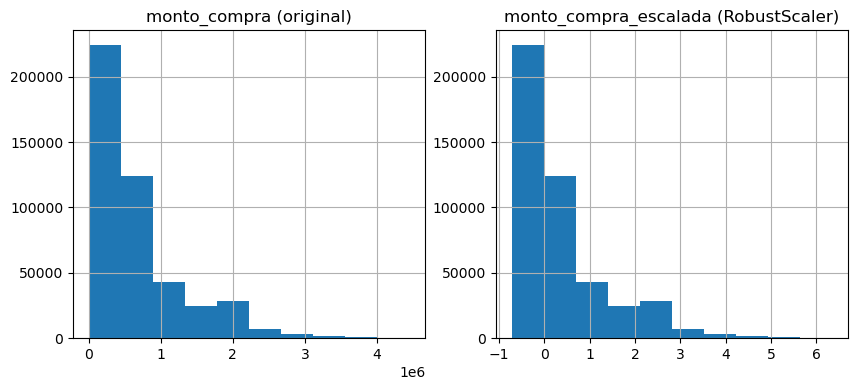

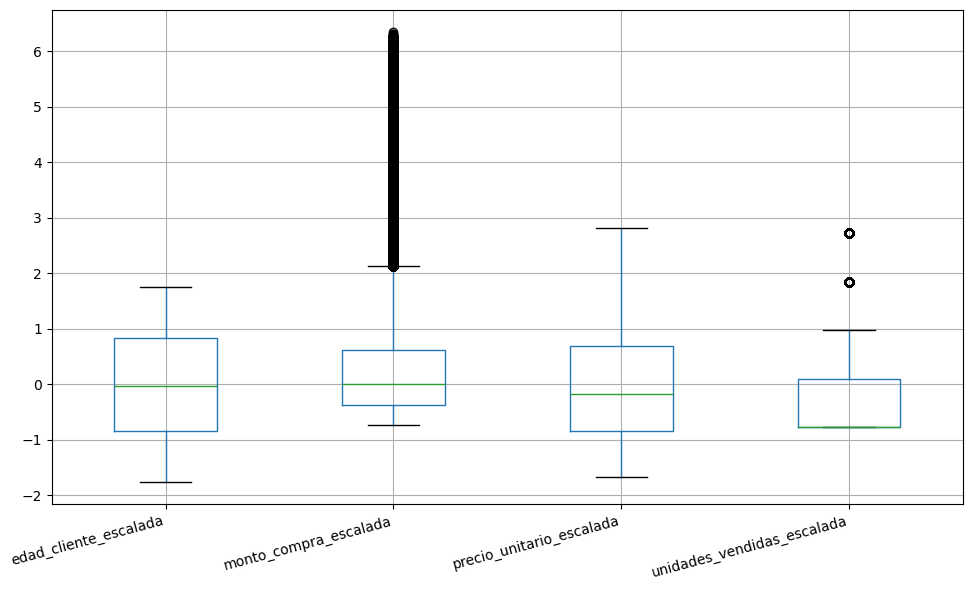


Shape de salida: (570976, 30)


In [6]:
def escalar_dataset(df, test_size=0.2, random_state=42, graficar=True):
    df = df.copy()  # evita modificar el DataFrame original
    filas_entrada = len(df)
    print("Shape de entrada:", df.shape)

    # --- Rangos antes de escalar ---
    columnas = ["edad_cliente", "precio_unitario", "monto_compra", "unidades_vendidas"]
    print(df[columnas].describe())

    # --- Imputación de nulos en monto_compra (antes del split: no usa estadísticas agregadas) ---
    print("Nulos en monto_compra ANTES de imputar:", df["monto_compra"].isna().sum())
    df["monto_compra"] = df["monto_compra"].fillna(df["precio_unitario"] * df["unidades_vendidas"])
    print("Nulos en monto_compra DESPUÉS de imputar:", df["monto_compra"].isna().sum())

    # --- División entrenamiento / prueba ---
    df_entrenamiento, df_prueba = train_test_split(
        df, test_size=test_size, random_state=random_state
    )
    df_entrenamiento = df_entrenamiento.copy()
    df_prueba = df_prueba.copy()
    assert len(df_entrenamiento) + len(df_prueba) == filas_entrada

    # --- Escaladores: fit solo con entrenamiento, transform en ambos conjuntos ---
    escaladores = {
        "edad_cliente": StandardScaler(),
        "monto_compra": RobustScaler(),
        "precio_unitario": StandardScaler(),
        "unidades_vendidas": StandardScaler(),
    }
    for col, escalador in escaladores.items():
        escalador.fit(df_entrenamiento[[col]])
        df_entrenamiento[col + "_escalada"] = escalador.transform(df_entrenamiento[[col]])
        df_prueba[col + "_escalada"] = escalador.transform(df_prueba[[col]])

    escaladas = [c + "_escalada" for c in escaladores]
    print("\nColumnas escaladas (entrenamiento):")
    print(df_entrenamiento[escaladas].describe())
    print("\nColumnas escaladas (prueba):")
    print(df_prueba[escaladas].describe())

    # --- Antes y después de monto_compra, y las 4 variables en una misma escala ---
    if graficar:
        fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
        df_entrenamiento["monto_compra"].hist(ax=ejes[0])
        df_entrenamiento["monto_compra_escalada"].hist(ax=ejes[1])
        ejes[0].set_title("monto_compra (original)")
        ejes[1].set_title("monto_compra_escalada (RobustScaler)")
        plt.show()

        plt.figure(figsize=(10, 6))
        df_entrenamiento[escaladas].boxplot()
        plt.xticks(rotation=15, ha="right")
        plt.tight_layout()
        plt.show()

    # --- Unir entrenamiento y prueba en un solo df para la siguiente etapa ---
    # reset_index deja el df como si se hubiera releído el CSV de la semana 8 (índice 0..n-1)
    df = pd.concat([df_entrenamiento, df_prueba]).reset_index(drop=True)
    assert len(df) == filas_entrada
    print("\nShape de salida:", df.shape)

    return df, df_entrenamiento, df_prueba, escaladores


# Uso
df, df_entrenamiento, df_prueba, escaladores = escalar_dataset(df)

## Etapa 4: Codificación de variables categóricas

In [7]:
def codificar_dataset(df, test_size=0.2, random_state=42, umbral_postal=15):
    """
    Recibe un DataFrame (ya escalado), codifica las variables categóricas
    y divide en entrenamiento y prueba.

    - One-hot: categoria_producto, metodo_pago, canal_compra
    - Ordinal: nivel_lealtad (Bronce < Plata < Oro < Platino)
    - Target encoding: ciudad_tienda (ajustado solo con entrenamiento)
    - Agrupación de categorías raras: codigo_postal (frecuencias solo de entrenamiento)

    No exporta archivos: el único guardado del pipeline está al final del notebook.

    Retorna: df (entrenamiento + prueba unidos, para la siguiente etapa),
             df_entrenamiento, df_prueba, codificador_lealtad, codificador_ciudad
    """
    df = df.copy()  # evita modificar el DataFrame original
    print("Shape de entrada:", df.shape)

    # --- Ordinal encoding: nivel_lealtad (orden explícito, no alfabético) ---
    orden_lealtad = ["Bronce", "Plata", "Oro", "Platino"]
    codificador_lealtad = OrdinalEncoder(categories=[orden_lealtad])
    df["nivel_lealtad_cod"] = codificador_lealtad.fit_transform(df[["nivel_lealtad"]])
    print("nivel_lealtad_cod:", df["nivel_lealtad_cod"].value_counts().sort_index().to_dict())

    # --- One-hot encoding: nominales de baja cardinalidad ---
    df_codificado = pd.get_dummies(
        df,
        columns=["categoria_producto", "metodo_pago", "canal_compra"],
        prefix=["cat", "pago", "canal"],
    )
    print("Shape después de one-hot:", df_codificado.shape)

    # --- División entrenamiento / prueba (sobre el df ya codificado) ---
    df_entrenamiento, df_prueba = train_test_split(
        df_codificado, test_size=test_size, random_state=random_state
    )
    df_entrenamiento = df_entrenamiento.copy()
    df_prueba = df_prueba.copy()
    assert len(df_entrenamiento) + len(df_prueba) == len(df_codificado)

    # --- Target encoding: ciudad_tienda (solo se ajusta con entrenamiento) ---
    codificador_ciudad = TargetEncoder(cols=["ciudad_tienda"], smoothing=10)
    codificador_ciudad.fit(df_entrenamiento[["ciudad_tienda"]],
                           df_entrenamiento["monto_compra"])

    df_entrenamiento["ciudad_tienda_cod"] = codificador_ciudad.transform(
        df_entrenamiento[["ciudad_tienda"]]
    )["ciudad_tienda"]
    df_prueba["ciudad_tienda_cod"] = codificador_ciudad.transform(
        df_prueba[["ciudad_tienda"]]
    )["ciudad_tienda"]
    print("\nTarget encoding por ciudad (entrenamiento):")
    print(df_entrenamiento.groupby("ciudad_tienda")["ciudad_tienda_cod"].first().round(0).sort_values().to_string())

    # --- Agrupar códigos postales poco frecuentes ---
    # Las frecuencias se calculan solo con entrenamiento y se aplican a ambos
    conteo_postal = df_entrenamiento["codigo_postal"].astype(str).value_counts()
    postales_frecuentes = conteo_postal[conteo_postal >= umbral_postal].index

    for d in (df_entrenamiento, df_prueba):
        cp = d["codigo_postal"].astype(str)
        d["codigo_postal_agrupado"] = cp.where(cp.isin(postales_frecuentes), "Otras")
    print(f"\ncodigo_postal: {len(conteo_postal)} códigos -> {len(postales_frecuentes)} frecuentes + 'Otras' "
          f"({(df_entrenamiento['codigo_postal_agrupado'] == 'Otras').mean():.1%} de entrenamiento en 'Otras')")

    # --- Unir entrenamiento y prueba en un solo df para la siguiente etapa ---
    df_salida = pd.concat([df_entrenamiento, df_prueba]).reset_index(drop=True)
    assert len(df_salida) == len(df_codificado)
    print("\nShape de salida:", df_salida.shape,
          "| entrenamiento:", df_entrenamiento.shape, "| prueba:", df_prueba.shape)

    return df_salida, df_entrenamiento, df_prueba, codificador_lealtad, codificador_ciudad


# Uso (df viene de la etapa anterior)
df, df_entrenamiento, df_prueba, codificador_lealtad, codificador_ciudad = codificar_dataset(df)

Shape de entrada: (570976, 30)
nivel_lealtad_cod: {0.0: 142649, 1.0: 143479, 2.0: 142607, 3.0: 142241}
Shape después de one-hot: (570976, 42)

Target encoding por ciudad (entrenamiento):
ciudad_tienda
Villavicencio    649730.0
Bogotá           650514.0
Bucaramanga      651106.0
Barranquilla     651264.0
Cali             652881.0
Manizales        653055.0
Santa Marta      654422.0
Ibagué           654989.0
Medellín         655527.0
Cúcuta           656794.0
Pereira          657102.0
Cartagena        659721.0

codigo_postal: 492 códigos -> 301 frecuentes + 'Otras' (0.2% de entrenamiento en 'Otras')

Shape de salida: (570976, 44) | entrenamiento: (456780, 44) | prueba: (114196, 44)


## Etapa 5: Transformaciones de fecha, texto y discretización

In [8]:
def transformar_dataset(df, test_size=0.2, random_state=42):
    """
    Recibe un DataFrame ya codificado, crea variables temporales, de texto
    y de edad, aplica transformaciones al monto y divide en entrenamiento
    y prueba.

    Retorna: df (con las nuevas columnas), df_entrenamiento, df_prueba, transformador
    """
    df = df.copy()  # evita modificar el DataFrame original
    print("Dimensiones de entrada:", df.shape)

    # --- Variables temporales ---
    # Si fecha_pedido aún es texto (formatos mixtos ISO / D-M-Y), se convierte por elemento;
    # lo que no se pueda interpretar queda como NaT en vez de romper la celda.
    if not pd.api.types.is_datetime64_any_dtype(df["fecha_pedido"]):
        df["fecha_pedido"] = pd.to_datetime(
            df["fecha_pedido"], format="mixed", dayfirst=True, errors="coerce"
        )
    n_nat = df["fecha_pedido"].isna().sum()
    if n_nat:
        print(f"Aviso: {n_nat} fechas nulas/no interpretables (NaT); sus variables temporales quedarán vacías.")
    print("Rango de fechas:", df["fecha_pedido"].min().date(), "a", df["fecha_pedido"].max().date())

    df["mes_pedido"] = df["fecha_pedido"].dt.month
    df["trimestre_pedido"] = df["fecha_pedido"].dt.quarter
    df["dia_semana_pedido"] = df["fecha_pedido"].dt.day_name()
    df["es_fin_semana_pedido"] = df["fecha_pedido"].dt.dayofweek >= 5

    # --- Variables de texto ---
    df["comentario_cliente"] = df["comentario_cliente"].fillna("")
    df["longitud_comentario"] = df["comentario_cliente"].str.len()
    df["num_palabras_comentario"] = df["comentario_cliente"].str.split().str.len()
    df["tiene_comentario"] = df["longitud_comentario"] > 0
    df["menciona_demora"] = df["comentario_cliente"].str.contains(
        "tarde|demora|retraso|no llegó", case=False, na=False
    )
    print(f"Con comentario: {df['tiene_comentario'].mean():.1%} | menciona demora: {df['menciona_demora'].mean():.1%}")

    # --- Grupos de edad ---
    df["grupo_edad"] = pd.cut(
        df["edad_cliente"],
        bins=[17, 25, 35, 45, 60, 100],
        labels=["18 a 25", "26 a 35", "36 a 45", "46 a 60", "61 y más"],
    )
    if df["grupo_edad"].isna().any():
        print("Aviso: hay edades fuera del rango 18-100 (quedaron como NaN).")
    print("\nDistribución de grupo_edad:")
    print(df["grupo_edad"].value_counts(dropna=False).sort_index().to_string())

    # --- Transformación logarítmica ---
    print("\nAsimetría de monto_compra:", round(df["monto_compra"].skew(), 2))
    df["monto_compra_log"] = np.log1p(df["monto_compra"])
    print("Asimetría de monto_compra_log:", round(df["monto_compra_log"].skew(), 2))

    # --- División entrenamiento / prueba ---
    df_entrenamiento, df_prueba = train_test_split(
        df, test_size=test_size, random_state=random_state
    )
    df_entrenamiento = df_entrenamiento.copy()
    df_prueba = df_prueba.copy()

    # --- Transformación de potencia (ajustada solo con entrenamiento) ---
    metodo = "box-cox" if (df_entrenamiento["monto_compra"] > 0).all() else "yeo-johnson"
    print("\nMétodo de transformación de potencia:", metodo)

    transformador = PowerTransformer(method=metodo)
    transformador.fit(df_entrenamiento[["monto_compra"]])

    df_entrenamiento["monto_compra_boxcox"] = transformador.transform(
        df_entrenamiento[["monto_compra"]]
    )
    df_prueba["monto_compra_boxcox"] = transformador.transform(
        df_prueba[["monto_compra"]]
    )
    print("Asimetría de monto_compra_boxcox (entrenamiento):",
          round(df_entrenamiento["monto_compra_boxcox"].skew(), 2))

    nuevas = ["mes_pedido", "trimestre_pedido", "dia_semana_pedido", "es_fin_semana_pedido",
              "longitud_comentario", "num_palabras_comentario", "tiene_comentario",
              "menciona_demora", "grupo_edad", "monto_compra_log", "monto_compra_boxcox"]
    print("\nMuestra de variables nuevas (entrenamiento):")
    print(df_entrenamiento[nuevas].head().to_string())
    print("\nShape -> entrenamiento:", df_entrenamiento.shape, "| prueba:", df_prueba.shape)

    return df, df_entrenamiento, df_prueba, transformador


# Uso (df viene de la etapa anterior)
df, df_entrenamiento, df_prueba, transformador = transformar_dataset(df)

Dimensiones de entrada: (570976, 44)
Aviso: 20288 fechas nulas/no interpretables (NaT); sus variables temporales quedarán vacías.
Rango de fechas: 2025-01-01 a 2027-12-28
Con comentario: 85.8% | menciona demora: 0.0%

Distribución de grupo_edad:
grupo_edad
18 a 25      74109
26 a 35      92455
36 a 45      93068
46 a 60     172356
61 y más    138988

Asimetría de monto_compra: 1.69
Asimetría de monto_compra_log: -2.94

Método de transformación de potencia: yeo-johnson
Asimetría de monto_compra_boxcox (entrenamiento): -0.42

Muestra de variables nuevas (entrenamiento):
        mes_pedido  trimestre_pedido dia_semana_pedido  es_fin_semana_pedido  longitud_comentario  num_palabras_comentario  tiene_comentario  menciona_demora grupo_edad  monto_compra_log  monto_compra_boxcox
267455         5.0               2.0            Monday                 False                   24                        4              True            False    36 a 45         10.815790            -1.267554
518180   

## Exportación final

In [9]:
# ÚNICA SALIDA del pipeline: entrenamiento + prueba con todas las columnas de las semanas 6 a 10
RUTA_SALIDA = "S11_PD_Lozano_DatasetTransformado.csv"

df_final = pd.concat([
    df_entrenamiento.assign(conjunto="entrenamiento"),
    df_prueba.assign(conjunto="prueba"),
]).reset_index(drop=True)

df_final.to_csv(RUTA_SALIDA, index=False)

print("Guardado en:", RUTA_SALIDA)
print("Shape final:", df_final.shape)
print(df_final["conjunto"].value_counts().to_string())
print("\nColumnas con nulos:")
nulos = df_final.isna().sum()
print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "ninguna")

Guardado en: S11_PD_Lozano_DatasetTransformado.csv
Shape final: (570976, 56)
conjunto
entrenamiento    456780
prueba           114196

Columnas con nulos:
fecha_pedido         20288
correo_cliente       93831
mes_pedido           20288
trimestre_pedido     20288
dia_semana_pedido    20288


## Diccionario de datos de las semanas 8, 9 y 10



| Columna del dataset | De qué semana viene | Qué significa |
|---|---|---|
| `edad_cliente_escalada` | Semana 8 | `edad_cliente` estandarizada con Z-score (`StandardScaler` ajustado solo con entrenamiento). Se conserva junto a la original |
| `monto_compra_escalada` | Semana 8 | `monto_compra` con escalado robusto (`RobustScaler`: mediana e IQR de entrenamiento), para que la cola de ventas corporativas no distorsione la escala |
| `precio_unitario_escalada` | Semana 8 | `precio_unitario` estandarizada con Z-score (`StandardScaler` ajustado solo con entrenamiento) |
| `unidades_vendidas_escalada` | Semana 8 | `unidades_vendidas` estandarizada con Z-score (`StandardScaler` ajustado solo con entrenamiento) |
| `cat_<categoría>` | Semana 9 | Variables dummy (one-hot) de `categoria_producto`: una columna por categoría (6). Vale 1 si el pedido es de esa categoría y 0 si no |
| `pago_<método>` | Semana 9 | Variables dummy (one-hot) de `metodo_pago`: una columna por método de pago (4) |
| `canal_<canal>` | Semana 9 | Variables dummy (one-hot) de `canal_compra`: una columna por canal (4) |
| `nivel_lealtad_cod` | Semana 9 | Nivel de lealtad codificado en su orden real: Bronce=0, Plata=1, Oro=2, Platino=3 |
| `ciudad_tienda_cod` | Semana 9 | Target encoding de `ciudad_tienda`: promedio suavizado (smoothing=10) de `monto_compra` por ciudad, calculado solo con entrenamiento |
| `codigo_postal_agrupado` | Semana 9 | `codigo_postal` donde los códigos con menos de 15 pedidos en entrenamiento se agrupan como "Otras" |
| `mes_pedido` | Semana 10 | Mes en que se hizo el pedido (1 a 12), extraído de `fecha_pedido` |
| `trimestre_pedido` | Semana 10 | Trimestre del año del pedido (1 a 4), extraído de `fecha_pedido` |
| `dia_semana_pedido` | Semana 10 | Nombre del día de la semana del pedido (Monday, Tuesday, ...) |
| `es_fin_semana_pedido` | Semana 10 | True si el pedido se hizo en sábado o domingo, False en caso contrario |
| `longitud_comentario` | Semana 10 | Número de caracteres de `comentario_cliente` (0 si no hay comentario) |
| `num_palabras_comentario` | Semana 10 | Número de palabras de `comentario_cliente` |
| `tiene_comentario` | Semana 10 | True si el cliente dejó un comentario, False si el campo estaba vacío |
| `menciona_demora` | Semana 10 | True si el comentario contiene "tarde", "demora", "retraso" o "no llegó" |
| `grupo_edad` | Semana 10 | Rango de edad del cliente: 18 a 25, 26 a 35, 36 a 45, 46 a 60, 61 y más |
| `monto_compra_log` | Semana 10 | Logaritmo natural de (1 + `monto_compra`), para reducir su sesgo |
| `monto_compra_boxcox` | Semana 10 | `monto_compra` transformado con PowerTransformer (Box-Cox, o Yeo-Johnson si hay valores ≤ 0), ajustado solo con entrenamiento. Se calcula después de dividir en entrenamiento y prueba |
| `conjunto` | Exportación final | Indica si la fila pertenece al conjunto de `entrenamiento` o de `prueba`. Solo se agrega al guardar el archivo final |
